# Model run

In [1]:
# Set scenario name
SCENARIO_NAME = 'current_hospitals'

In [2]:
import contextily as ctx
import geopandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classes.geography_processing import Geoprocessing
from classes.model import Model
from classes.scenario import Scenario


In [3]:
SCENARIO_NAME = 'taunton_and_worcester'
NEW_MT_CENTRES = ['TA15DA', 'WR51DD']

In [4]:
# Allow for a travel bias time (minutes) to MT centres
MT_travel_bias = 5

# Process and save geographic data (only needed when hospital data changes)
geo = Geoprocessing(mt_travel_bias = MT_travel_bias, new_mt_centres = NEW_MT_CENTRES)
geo.run()

# Set up scenario
scenario = Scenario({
    'name': SCENARIO_NAME,
    'limit_to_england' : True
})

# Set up model
model = Model(
    scenario=scenario,
    geodata=pd.read_csv('processed_data/processed_data.csv'))

# Run model
model.run()


The input mRS distributions might be improperly labelled.
The input mRS distributions might be improperly labelled.


In [5]:
model.full_results.to_csv(f'./output/results_full_{SCENARIO_NAME}.csv')

In [6]:
results = model.full_results

In [7]:
# Add net benefit column
prop_nlvo = 0.7
prop_lvo = 1 - prop_nlvo

# Utility

results['drip_ship_utility_shift'] = (
    (results['nlvo_drip_ship_ivt_utility_shift'] * prop_nlvo) +
    (results['lvo_drip_ship_ivt_mt_utility_shift'] * prop_lvo))

results['mothership_utility_shift'] = (
    (results['nlvo_mothership_ivt_utility_shift'] * prop_nlvo) +
    (results['lvo_mothership_ivt_mt_utility_shift'] * prop_lvo))

# Get mRS 0-2 improvements
results['nlvo_drip_ship_ivt_improvement_over_no_treatment'] = \
    results['nlvo_drip_ship_ivt_mrs_0-2'] - results['nlvo_no_treatment_mrs_0-2']
results['lvo_drip_ship_ivt_improvement_over_no_treatment'] = \
    results['lvo_drip_ship_ivt_mrs_0-2'] - results['lvo_no_treatment_mrs_0-2']

# Get proportions mRS 0-2 for each scenario
results['no_treatment_mrs_0-2'] = (
    (results['nlvo_no_treatment_mrs_0-2'] * prop_nlvo) +
    (results['lvo_no_treatment_mrs_0-2'] * prop_lvo))

results['drip_ship_mrs_0-2'] = (
    (results['nlvo_drip_ship_ivt_mrs_0-2'] * prop_nlvo) +
    (results['lvo_drip_ship_mt_mrs_0-2'] * prop_lvo))

results['drip_ship_mrs_0-2_improvement_over_no_treatment'] = \
    results['drip_ship_mrs_0-2'] - results['no_treatment_mrs_0-2']

results['mothership_mrs_0-2'] = (
    (results['nlvo_mothership_ivt_mrs_0-2'] * prop_nlvo) +
    (results['lvo_mothership_ivt_mt_mrs_0-2'] * prop_lvo))

results['mothership_mrs_0-2_improvement_over_no_treatment'] = \
    results['mothership_mrs_0-2'] - results['no_treatment_mrs_0-2']

In [8]:
results.head()

,nearest_ivt_unit,nearest_ivt_time,nearest_ivt_unit_no_bias,nearest_ivt_time_no_bias,nearest_mt_unit,nearest_mt_time,transfer_unit,transfer_required,transfer_time,area_lower,...,lvo_mothership_ivt_mt_utility_shift,drip_ship_utility_shift,mothership_utility_shift,nlvo_drip_ship_ivt_improvement_over_no_treatment,lvo_drip_ship_ivt_improvement_over_no_treatment,no_treatment_mrs_0-2,drip_ship_mrs_0-2,drip_ship_mrs_0-2_improvement_over_no_treatment,mothership_mrs_0-2,mothership_mrs_0-2_improvement_over_no_treatment
LSOA,,,,,,,,,,,,,,,,,,,,,
ADUR001A,BN25BE,6,BN25BE,11,BN25BE,11,BN25BE,False,0,Adur 001A,...,0.155584,0.116280,0.124652,0.122743,0.061337,0.4855,0.610213,0.124713,0.619167,0.133667
ADUR001B,BN25BE,7,BN25BE,12,BN25BE,12,BN25BE,False,0,Adur 001B,...,0.154986,0.115817,0.124185,0.122294,0.061045,0.4855,0.609711,0.124211,0.618658,0.133158
ADUR001C,BN25BE,8,BN112DH,11,BN25BE,13,BN25BE,False,0,Adur 001C,...,0.154388,0.115354,0.123719,0.121846,0.060754,0.4855,0.609208,0.123708,0.618149,0.132649
ADUR001D,BN25BE,7,BN25BE,12,BN25BE,12,BN25BE,False,0,Adur 001D,...,0.154986,0.115817,0.124185,0.122294,0.061045,0.4855,0.609711,0.124211,0.618658,0.133158
ADUR001E,BN25BE,8,BN112DH,10,BN25BE,13,BN25BE,False,0,Adur 001E,...,0.154388,0.115354,0.123719,0.121846,0.060754,0.4855,0.609208,0.123708,0.618149,0.132649


In [9]:
# Get descriptive stats for all numeric columns
descriptive_stats = results.describe(percentiles=[0.25, 0.5, 0.75]).T
descriptive_stats.to_csv(f'./output/results_stats_{SCENARIO_NAME}.csv')
descriptive_stats

,count,mean,std,min,25%,50%,75%,max
nearest_ivt_time,32843.0,11.063301,8.266181e+00,-5.000000,5.000000,10.000000,16.000000,65.000000
nearest_ivt_time_no_bias,32843.0,13.123466,7.928949e+00,0.000000,7.000000,12.000000,17.000000,68.000000
nearest_mt_time,32843.0,24.175867,1.519412e+01,0.000000,13.000000,21.000000,32.000000,121.000000
transfer_time,32843.0,16.338032,1.806849e+01,0.000000,0.000000,17.000000,30.000000,104.000000
Admissions,32843.0,2.466063,1.418715e+00,0.100000,1.333333,2.333333,3.333333,19.333333
England,32843.0,1.000000,0.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000
Admissions_2025_Est,32843.0,2.763329,1.589728e+00,0.112050,1.494030,2.614580,3.735130,21.663830
drip_ship_ivt_time,32843.0,121.063301,8.266181e+00,105.000000,115.000000,120.000000,126.000000,175.000000
drip_ship_mt_time,32843.0,257.401334,2.189299e+01,225.000000,239.000000,255.000000,271.000000,362.000000
nlvo_no_treatment_mrs_0-2,32843.0,0.580000,0.000000e+00,0.580000,0.580000,0.580000,0.580000,0.580000


In [10]:
# Repeat descriptive stats, grouped by nearest_ivt_unit
results_stats_by_unit = results.groupby('nearest_ivt_unit').describe().T
# Unpack index column so two-level index becomes two columns
results_stats_by_unit = results_stats_by_unit.reset_index()
rename_dict = {'level_0': 'variable', 'level_1': 'statistic'}
results_stats_by_unit = results_stats_by_unit.rename(columns=rename_dict)
# Save
results_stats_by_unit.to_csv(f'./output/results_stats_by_unit_{SCENARIO_NAME}.csv')
results_stats_by_unit.head()

nearest_ivt_unit,variable,statistic,B152TH,B662QT,BA13NG,BB23HH,BD96RJ,BH77DW,BL97TD,BN112DH,...,TF16TF,TQ27AA,TR13LQ,TS198PE,TS43BW,WD180HB,WF14DG,WR51DD,WV100QP,YO318HE
0,nearest_ivt_time,count,747.000000,265.000000,273.000000,273.000000,311.000000,333.000000,339.000000,165.000000,...,229.000000,169.000000,243.000000,58.000000,465.000000,350.000000,243.000000,300.000000,426.000000,270.000000
1,nearest_ivt_time,mean,8.583668,8.826415,18.318681,12.311355,8.922830,11.456456,11.383481,9.624242,...,14.532751,10.763314,22.090535,6.379310,13.221505,12.151429,11.053498,10.856667,11.575117,20.100000
2,nearest_ivt_time,std,5.473495,4.558548,9.021069,6.021571,6.100277,5.225810,4.755609,7.030727,...,8.364766,6.995974,9.532460,4.564653,11.053181,5.377171,4.846531,7.466500,5.997665,15.737661
3,nearest_ivt_time,min,-3.000000,1.000000,1.000000,2.000000,0.000000,1.000000,0.000000,1.000000,...,2.000000,1.000000,1.000000,2.000000,-3.000000,1.000000,1.000000,-3.000000,2.000000,1.000000
4,nearest_ivt_time,25%,4.000000,5.000000,11.000000,7.000000,5.000000,7.000000,8.000000,4.000000,...,8.000000,5.000000,15.500000,4.000000,4.000000,8.000000,7.000000,4.750000,7.000000,6.000000


## Map

In [11]:
# Load the England and Wales LSOA shapefile
filename = "./data/Lower_layer_super_output_areas_(E+W)_2011_Boundaries_(Generalised_Clipped)_V2.zip"
lsoa_gdf = geopandas.read_file(filename)

# Set or convert to British National Grid (EPSG:27700)
if lsoa_gdf.crs is None:
    lsoa_gdf = lsoa_gdf.set_crs("EPSG:27700")
else:
    lsoa_gdf = lsoa_gdf.to_crs("EPSG:27700")

# Get the England and Wales outline
filename = "zip://./data/Countries_(December_2022)_GB_BFC.zip"
countries_gdf = geopandas.read_file(filename)
if countries_gdf.crs is None:
    countries_gdf = countries_gdf.set_crs("EPSG:27700")
else:
    countries_gdf = countries_gdf.to_crs("EPSG:27700")

mask = countries_gdf["CTRY22NM"].isin(["England", "Wales"])
countries_gdf = countries_gdf.loc[mask]
england = countries_gdf.boundary

# Load hospital coordinates from CSV and create a GeoDataFrame
hospitals_df = pd.read_csv("./data/stroke_hospitals_2025.csv")
hospitals_gdf = geopandas.GeoDataFrame(
    hospitals_df,
    geometry=geopandas.points_from_xy(
        pd.to_numeric(hospitals_df["long"]),
        pd.to_numeric(hospitals_df["lat"]),
    ),
    crs="EPSG:4326",
).to_crs("EPSG:27700")

hospitals_gdf = hospitals_gdf.loc[hospitals_gdf["Country"] == "England"]
hospitals_gdf.head()

# Change 'Use_MT' values for new MT centres to hospitals_gdf
if len(NEW_MT_CENTRES) > 0:
    for new_mt_centre in NEW_MT_CENTRES:
        hospitals_gdf.loc[hospitals_gdf['Postcode'] == new_mt_centre, 'Use_MT'] = 1

In [12]:
# Merge the results with the LSOA shapefile
data = lsoa_gdf.merge(results, left_on='LSOA11NM', right_on='area_lower', how='right')

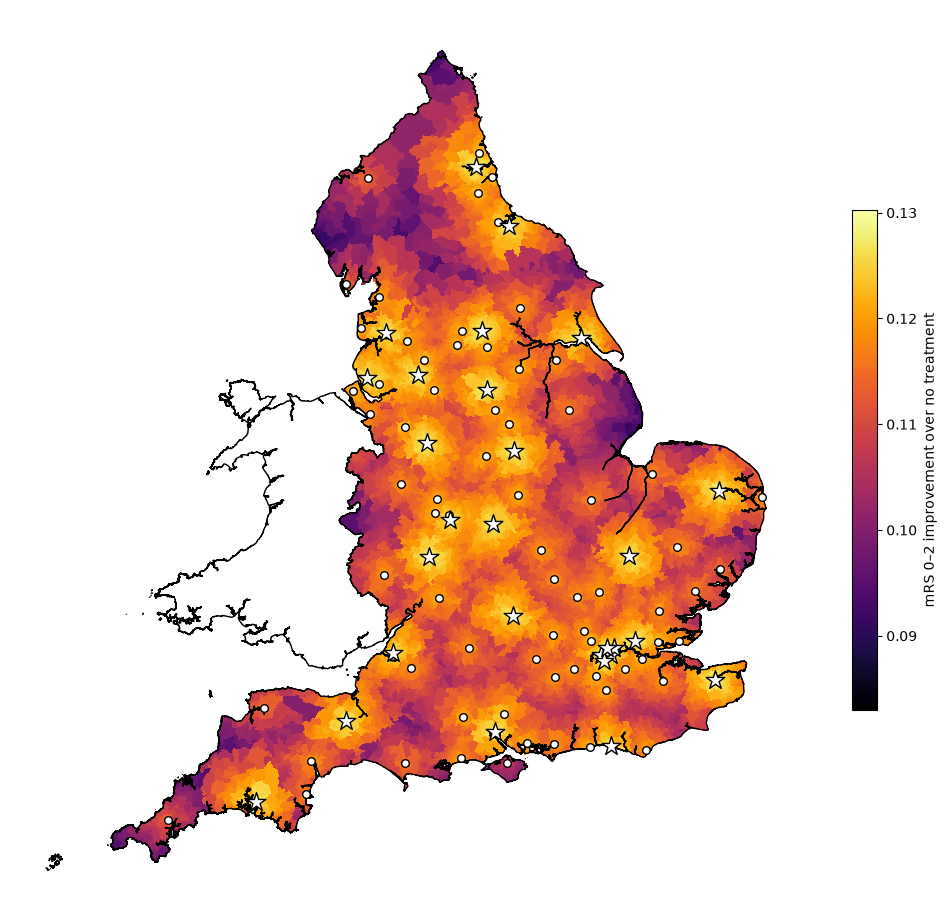

In [13]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

column = 'drip_ship_mrs_0-2_improvement_over_no_treatment'
values = pd.to_numeric(data[column], errors='coerce').astype(float)
valid_values = values.where(np.isfinite(values))

vmin, vmax = valid_values.min(), valid_values.max()
if vmin == vmax:
    vmax = vmin + 1

cmap = plt.get_cmap('inferno')
norm = Normalize(vmin=vmin, vmax=vmax)

# Use a temporary numeric column; GeoPandas handles the color mapping.
data['_plot_value'] = values

fig, ax = plt.subplots(figsize=(10, 10))
data.plot(
    column='_plot_value',
    ax=ax,
    cmap=cmap,
    vmin=vmin,
    vmax=vmax,
    missing_kwds={'color': 'lightgrey'},
    antialiased=False,
    linewidth=0,
)

england.plot(ax=ax, edgecolor='k', facecolor='none', linewidth=1)

ivt_mask = pd.to_numeric(hospitals_gdf['Use_IVT'], errors='coerce').eq(1)
mt_mask = pd.to_numeric(hospitals_gdf['Use_MT'], errors='coerce').eq(1)

hospitals_gdf.loc[ivt_mask].plot(
    ax=ax, edgecolor='k', facecolor='w', markersize=30, marker='o', zorder=99
)
hospitals_gdf.loc[mt_mask].plot(
    ax=ax, edgecolor='k', facecolor='w', markersize=200, marker='*', zorder=99
)

fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    shrink=0.5,
    label='mRS 0–2 improvement over no treatment',
)

#ax.margins(0)
ax.apply_aspect()
ax.set_axis_off()
plt.subplots_adjust(left=0.01, right=1.0, bottom=0.0, top=1.0)
plt.savefig(f'./output/map_drip_ship_mrs_0-2_improvement_over_no_treatment_{SCENARIO_NAME}.png', dpi=300, bbox_inches='tight')
plt.show()